## How do we turn the equations into Python code?

An SDE describes continuous-time behaviour, but a computer needs discrete time steps. We approximate the continuous process at times:

t₀, t₁, ..., tₙ

with

Δt = T / N

A basic Euler discretization gives:

Sₙ₊₁ = Sₙ + rSₙΔt + √Vₙ · Sₙ · √Δt · Z₁

Vₙ₊₁ = Vₙ + κ(θ − Vₙ)Δt + ξ√Vₙ · √Δt · Zᵥ

where

Zᵥ = ρZ₁ + √(1 − ρ²)Z₂

There is a subtle but important problem here: the Euler variance update can produce negative values, even though variance cannot be negative. We can use a positivity-preserving approximation, but a better approach for this particular repository is to first understand Euler and then study its exact variance sampling method.

The repository's exact variance sampler uses the non-central chi-squared distribution. This is more sophisticated than Euler and is an excellent topic to investigate once the basic mechanics are clear.

Here is a first, independent implementation you can run. It uses full-truncation Euler: negative variance estimates are replaced with zero when calculating the next step's coefficients, while the raw variance state is retained. It is useful for learning, but it is not identical to the repository's exact variance sampler.

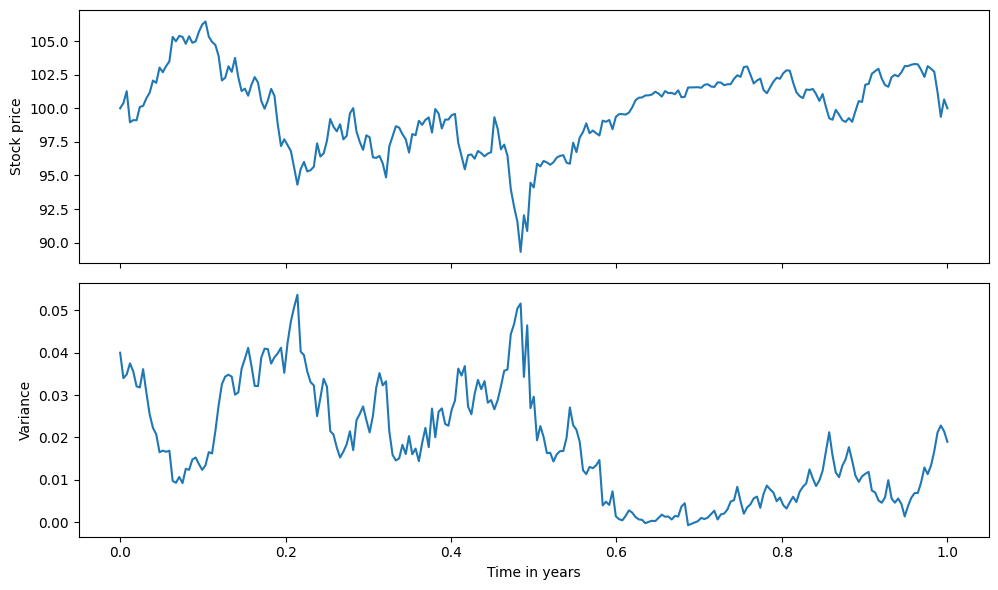

In [1]:

import numpy as np
import matplotlib.pyplot as plt


def simulate_heston(
    S0=100.0,
    v0=0.04,
    r=0.02,
    kappa=2.0,
    theta=0.04,
    xi=0.5,
    rho=-0.7,
    T=1.0,
    steps=252,
    seed=42,
):
    rng = np.random.default_rng(seed)
    dt = T / steps

    stock = np.empty(steps + 1)
    variance = np.empty(steps + 1)

    stock[0] = S0
    variance[0] = v0

    for t in range(steps):
        z1, z2 = rng.standard_normal(2)

        # Correlated Brownian shocks
        z_variance = rho * z1 + np.sqrt(1 - rho**2) * z2

        # Keep the current diffusion coefficients nonnegative
        v_positive = max(variance[t], 0.0)

        stock[t + 1] = stock[t] * (
            1 + r * dt
            + np.sqrt(v_positive * dt) * z1
        )

        variance[t + 1] = (
            variance[t]
            + kappa * (theta - v_positive) * dt
            + xi * np.sqrt(v_positive * dt) * z_variance
        )

    time = np.linspace(0, T, steps + 1)
    return time, stock, variance


time, stock, variance = simulate_heston()

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

axes[0].plot(time, stock)
axes[0].set_ylabel("Stock price")

axes[1].plot(time, variance)
axes[1].set_ylabel("Variance")
axes[1].set_xlabel("Time in years")

plt.tight_layout()
plt.show()


One caveat: the stock update above is an Euler approximation too, so it does not guarantee positive stock prices in every possible simulation. Later, we can improve it using a log-price formulation and compare discretization schemes systematically.

## The connection to JEPA thesis

This is where the project becomes particularly interesting.

Suppose you generate a dataset containing:

1. The observed stock-price paths: S0, S1, ..., ST
2. The underlying simulated variance paths: V0, V1, ..., VT
3. The model parameters used to generate them.

We can train a model using only stock price histories as input, then evaluate whether its learned representation captures information about the latent variance.

Small Caveat when making the claim: A model learning to predict future stock-price representations does not automatically mean it has leanred true volatility. Need an explicit evaluation against the simulated variance, sutiable basliens and tests under different parameter settings.

That is why the simulator must be correct and well validated efore moving onto JEP. Otherwise, we could end up measuring artefacts of the simulation method insteaf of meaningful volatility learning.